<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_2%EC%A1%B0_Project3_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **제주 특산물 가격 예측 경진대회**



In [1]:
# 1. 라이브러리 및 경로 설정
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_DIR = Path("/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)")

TRAIN_PATH = DATA_DIR / "/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/train.csv"
TEST_PATH = DATA_DIR / "/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/test.csv"
TRADE_PATH = DATA_DIR / "/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/international_trade.csv"
SUBMISSION_PATH = DATA_DIR / "/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/sample_submission.csv"

# 파일 존재 여부 확인
for path in [TRAIN_PATH, TEST_PATH, TRADE_PATH, SUBMISSION_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"파일을 찾을 수 없습니다: {path}")

print("모든 파일을 확인했습니다.")

모든 파일을 확인했습니다.


In [2]:
# 2. 데이터 불러오기
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
trade = pd.read_csv(TRADE_PATH)
sample_submission = pd.read_csv(SUBMISSION_PATH)

print("train:", train.shape)
print("test:", test.shape)
print("international_trade:", trade.shape)
print("sample_submission:", sample_submission.shape)

display(train.head())
display(test.head())
display(trade.head())
display(sample_submission.head())

train: (59397, 7)
test: (1092, 5)
international_trade: (1274, 7)
sample_submission: (1092, 2)


,ID,timestamp,item,corporation,location,supply(kg),price(원/kg)
0,TG_A_J_20190101,2019-01-01,TG,A,J,0.0,0.0
1,TG_A_J_20190102,2019-01-02,TG,A,J,0.0,0.0
2,TG_A_J_20190103,2019-01-03,TG,A,J,60601.0,1728.0
3,TG_A_J_20190104,2019-01-04,TG,A,J,25000.0,1408.0
4,TG_A_J_20190105,2019-01-05,TG,A,J,32352.0,1250.0


,ID,timestamp,item,corporation,location
0,TG_A_J_20230304,2023-03-04,TG,A,J
1,TG_A_J_20230305,2023-03-05,TG,A,J
2,TG_A_J_20230306,2023-03-06,TG,A,J
3,TG_A_J_20230307,2023-03-07,TG,A,J
4,TG_A_J_20230308,2023-03-08,TG,A,J


,기간,품목명,수출 중량,수출 금액,수입 중량,수입 금액,무역수지
0,2019-01,토마토(신선한 것이나 냉장한 것으로 한정한다),356571,990,0,0,990
1,2019-01,양파,821330,222,4003206,1118,-896
2,2019-01,쪽파,60,1,93405,128,-127
3,2019-01,꽃양배추와 브로콜리(broccoli),160,1,638913,563,-562
4,2019-01,방울다다기 양배추,0,0,7580,38,-38


,ID,answer
0,TG_A_J_20230304,0
1,TG_A_J_20230305,0
2,TG_A_J_20230306,0
3,TG_A_J_20230307,0
4,TG_A_J_20230308,0


In [3]:
# 3. 기본 구조 및 자료형 확인
for name, df in {
    "train": train,
    "test": test,
    "international_trade": trade,
    "sample_submission": sample_submission,
}.items():
    print(f"\\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print(df.dtypes)
    print("결측치 개수:\\n", df.isna().sum())

\n===== train =====
shape: (59397, 7)
columns: ['ID', 'timestamp', 'item', 'corporation', 'location', 'supply(kg)', 'price(원/kg)']
ID              object
timestamp       object
item            object
corporation     object
location        object
supply(kg)     float64
price(원/kg)    float64
dtype: object
결측치 개수:\n ID             0
timestamp      0
item           0
corporation    0
location       0
supply(kg)     0
price(원/kg)    0
dtype: int64
\n===== test =====
shape: (1092, 5)
columns: ['ID', 'timestamp', 'item', 'corporation', 'location']
ID             object
timestamp      object
item           object
corporation    object
location       object
dtype: object
결측치 개수:\n ID             0
timestamp      0
item           0
corporation    0
location       0
dtype: int64
\n===== international_trade =====
shape: (1274, 7)
columns: ['기간', '품목명', '수출 중량', '수출 금액', '수입 중량', '수입 금액', '무역수지']
기간       object
품목명      object
수출 중량     int64
수출 금액     int64
수입 중량     int64
수입 금액     int64
무역수지  

In [4]:
# 4. 날짜 및 자료형 정리
train = train.copy()
test = test.copy()
trade = trade.copy()
sample_submission = sample_submission.copy()

# 날짜 변환
train["timestamp"] = pd.to_datetime(train["timestamp"], errors="coerce")
test["timestamp"] = pd.to_datetime(test["timestamp"], errors="coerce")
trade["trade_month"] = pd.to_datetime(trade["기간"].astype(str) + "-01", errors="coerce")

# 범주형 식별자 정리
categorical_cols = ["item", "corporation", "location"]
for df in [train, test]:
    for col in categorical_cols:
        df[col] = df[col].astype("string").str.strip()
    df["ID"] = df["ID"].astype("string").str.strip()

# 수치형 변수 변환
for col in ["supply(kg)", "price(원/kg)"]:
    train[col] = pd.to_numeric(train[col], errors="coerce")

trade_numeric_cols = ["수출 중량", "수출 금액", "수입 중량", "수입 금액", "무역수지"]
for col in trade_numeric_cols:
    trade[col] = pd.to_numeric(trade[col], errors="coerce")

print("train 날짜:", train["timestamp"].min(), "~", train["timestamp"].max())
print("test 날짜:", test["timestamp"].min(), "~", test["timestamp"].max())
print("trade 월:", trade["trade_month"].min(), "~", trade["trade_month"].max())

train 날짜: 2019-01-01 00:00:00 ~ 2023-03-03 00:00:00
test 날짜: 2023-03-04 00:00:00 ~ 2023-03-31 00:00:00
trade 월: 2019-01-01 00:00:00 ~ 2023-02-01 00:00:00


In [5]:
# 5. 데이터 품질 및 구조 검증
KEY_COLS = ["item", "corporation", "location"]

# 결측치
print("[결측치]")
print("train:\\n", train.isna().sum())
print("test:\\n", test.isna().sum())
print("trade:\\n", trade.isna().sum())

# 중복 ID 및 중복 시계열 관측치
print("\\n[중복]")
print("train 중복 ID:", train["ID"].duplicated().sum())
print("test 중복 ID:", test["ID"].duplicated().sum())
print("train 중복 (날짜, 품목, 법인, 지역):", train.duplicated(["timestamp"] + KEY_COLS).sum())

# ID가 식별자 조합과 일치하는지 확인
expected_train_id = (
    train["item"].astype(str) + "_" +
    train["corporation"].astype(str) + "_" +
    train["location"].astype(str) + "_" +
    train["timestamp"].dt.strftime("%Y%m%d")
)
expected_test_id = (
    test["item"].astype(str) + "_" +
    test["corporation"].astype(str) + "_" +
    test["location"].astype(str) + "_" +
    test["timestamp"].dt.strftime("%Y%m%d")
)
print("train ID 불일치:", (train["ID"].astype(str) != expected_train_id).sum())
print("test ID 불일치:", (test["ID"].astype(str) != expected_test_id).sum())

# 시계열 조합 수 및 각 조합별 날짜 수
print("\\n[시계열 조합]")
print("train 조합 수:", train[KEY_COLS].drop_duplicates().shape[0])
print("test 조합 수:", test[KEY_COLS].drop_duplicates().shape[0])
print("train 조합별 행 수:\\n", train.groupby(KEY_COLS, observed=True).size().value_counts().sort_index())
print("test 조합별 행 수:\\n", test.groupby(KEY_COLS, observed=True).size().value_counts().sort_index())

# 학습과 테스트의 품목-법인-지역 조합이 동일한지 확인
train_keys = set(map(tuple, train[KEY_COLS].drop_duplicates().to_numpy()))
test_keys = set(map(tuple, test[KEY_COLS].drop_duplicates().to_numpy()))
print("train/test 조합 동일:", train_keys == test_keys)

# 제출 파일과 테스트 ID 일치 여부
print("sample_submission과 test ID 순서 일치:", sample_submission["ID"].astype(str).tolist() == test["ID"].astype(str).tolist())

# 날짜 연속성 확인
train_days = pd.date_range(train["timestamp"].min(), train["timestamp"].max(), freq="D")
test_days = pd.date_range(test["timestamp"].min(), test["timestamp"].max(), freq="D")
print("train 전체 날짜 수:", len(train_days), "/ 실제 날짜 수:", train["timestamp"].nunique())
print("test 전체 날짜 수:", len(test_days), "/ 실제 날짜 수:", test["timestamp"].nunique())

[결측치]
train:\n ID             0
timestamp      0
item           0
corporation    0
location       0
supply(kg)     0
price(원/kg)    0
dtype: int64
test:\n ID             0
timestamp      0
item           0
corporation    0
location       0
dtype: int64
trade:\n 기간             0
품목명            0
수출 중량          0
수출 금액          0
수입 중량          0
수입 금액          0
무역수지           0
trade_month    0
dtype: int64
\n[중복]
train 중복 ID: 0
test 중복 ID: 0
train 중복 (날짜, 품목, 법인, 지역): 0
train ID 불일치: 0
test ID 불일치: 0
\n[시계열 조합]
train 조합 수: 39
test 조합 수: 39
train 조합별 행 수:\n 1523    39
Name: count, dtype: int64
test 조합별 행 수:\n 28    39
Name: count, dtype: int64
train/test 조합 동일: True
sample_submission과 test ID 순서 일치: True
train 전체 날짜 수: 1523 / 실제 날짜 수: 1523
test 전체 날짜 수: 28 / 실제 날짜 수: 28


가격 0 및 공급량 0 확인

In [6]:
zero_price = train["price(원/kg)"].eq(0)
zero_supply = train["supply(kg)"].eq(0)

zero_summary = pd.DataFrame({
    "구분": ["전체", "가격 0", "공급량 0", "가격·공급량 모두 0", "공급량 양수·가격 0", "공급량 0·가격 양수"],
    "건수": [
        len(train),
        int(zero_price.sum()),
        int(zero_supply.sum()),
        int((zero_price & zero_supply).sum()),
        int((~zero_supply & zero_price).sum()),
        int((zero_supply & ~zero_price).sum()),
    ],
})
zero_summary["비율(%)"] = zero_summary["건수"] / len(train) * 100
display(zero_summary)

# 공급량은 양수지만 가격이 0인 관측치 확인
anomalies = train[(train["supply(kg)"] > 0) & (train["price(원/kg)"] == 0)]
display(anomalies)

# 가격/공급량의 음수 여부 확인
print("음수 가격:", (train["price(원/kg)"] < 0).sum())
print("음수 공급량:", (train["supply(kg)"] < 0).sum())

,구분,건수,비율(%)
0,전체,59397,100.000000
1,가격 0,35455,59.691567
2,공급량 0,35452,59.686516
3,가격·공급량 모두 0,35452,59.686516
4,공급량 양수·가격 0,3,0.005051
5,공급량 0·가격 양수,0,0.000000


,ID,timestamp,item,corporation,location,supply(kg),price(원/kg)
825,TG_A_J_20210405,2021-04-05,TG,A,J,64.0,0.0
9266,TG_D_J_20190509,2019-05-09,TG,D,J,129.0,0.0
31199,CB_E_J_20210109,2021-01-09,CB,E,J,80.0,0.0


음수 가격: 0
음수 공급량: 0


날짜 및 품목 파생변수 생성

In [7]:
ITEM_NAME = {
    "TG": "감귤",
    "BC": "브로콜리",
    "RD": "무(월동무)",
    "CR": "당근",
    "CB": "양배추",
}

BASE_DATE = pd.Timestamp("2019-01-01")

def add_calendar_features(df):
    out = df.copy()
    ts = out["timestamp"]

    out["item_name"] = out["item"].map(ITEM_NAME)
    out["year"] = ts.dt.year.astype("int16")
    out["month"] = ts.dt.month.astype("int8")
    out["day"] = ts.dt.day.astype("int8")
    out["dayofweek"] = ts.dt.dayofweek.astype("int8")  # 월요일=0, 일요일=6
    out["dayofyear"] = ts.dt.dayofyear.astype("int16")
    out["weekofyear"] = ts.dt.isocalendar().week.astype("int16")
    out["quarter"] = ts.dt.quarter.astype("int8")
    out["is_weekend"] = ts.dt.dayofweek.isin([5, 6]).astype("int8")
    out["days_from_start"] = (ts - BASE_DATE).dt.days.astype("int32")

    # 월 주기: 1월과 12월이 서로 가까운 값이 되도록 원형 인코딩
    out["month_sin"] = np.sin(2 * np.pi * (out["month"] - 1) / 12)
    out["month_cos"] = np.cos(2 * np.pi * (out["month"] - 1) / 12)

    # 요일 주기
    out["dayofweek_sin"] = np.sin(2 * np.pi * out["dayofweek"] / 7)
    out["dayofweek_cos"] = np.cos(2 * np.pi * out["dayofweek"] / 7)
    return out

train_prepared = add_calendar_features(train)
test_prepared = add_calendar_features(test)

display(train_prepared.head())
display(test_prepared.head())

,ID,timestamp,item,corporation,location,supply(kg),price(원/kg),item_name,year,month,day,dayofweek,dayofyear,weekofyear,quarter,is_weekend,days_from_start,month_sin,month_cos,dayofweek_sin,dayofweek_cos
0,TG_A_J_20190101,2019-01-01,TG,A,J,0.0,0.0,감귤,2019,1,1,1,1,1,1,0,0,0.0,1.0,0.781831,0.623490
1,TG_A_J_20190102,2019-01-02,TG,A,J,0.0,0.0,감귤,2019,1,2,2,2,1,1,0,1,0.0,1.0,0.974928,-0.222521
2,TG_A_J_20190103,2019-01-03,TG,A,J,60601.0,1728.0,감귤,2019,1,3,3,3,1,1,0,2,0.0,1.0,0.433884,-0.900969
3,TG_A_J_20190104,2019-01-04,TG,A,J,25000.0,1408.0,감귤,2019,1,4,4,4,1,1,0,3,0.0,1.0,-0.433884,-0.900969
4,TG_A_J_20190105,2019-01-05,TG,A,J,32352.0,1250.0,감귤,2019,1,5,5,5,1,1,1,4,0.0,1.0,-0.974928,-0.222521


,ID,timestamp,item,corporation,location,item_name,year,month,day,dayofweek,dayofyear,weekofyear,quarter,is_weekend,days_from_start,month_sin,month_cos,dayofweek_sin,dayofweek_cos
0,TG_A_J_20230304,2023-03-04,TG,A,J,감귤,2023,3,4,5,63,9,1,1,1523,0.866025,0.5,-0.974928,-0.222521
1,TG_A_J_20230305,2023-03-05,TG,A,J,감귤,2023,3,5,6,64,9,1,1,1524,0.866025,0.5,-0.781831,0.623490
2,TG_A_J_20230306,2023-03-06,TG,A,J,감귤,2023,3,6,0,65,10,1,0,1525,0.866025,0.5,0.000000,1.000000
3,TG_A_J_20230307,2023-03-07,TG,A,J,감귤,2023,3,7,1,66,10,1,0,1526,0.866025,0.5,0.781831,0.623490
4,TG_A_J_20230308,2023-03-08,TG,A,J,감귤,2023,3,8,2,67,10,1,0,1527,0.866025,0.5,0.974928,-0.222521


국제 거래 데이터 전처리 및 결합

- TG 감귤 ↔ 감귤
- BC 브로콜리 ↔ 꽃양배추와 브로콜리(broccoli) (브로콜리만이 아닌 복합 분류이므로 대리 지표)
- CR 당근 ↔ 당근
- CB 양배추 ↔ 양배추
- RD 무 ↔ 직접 대응되는 무 품목을 확인하지 못함. 무화과와 순무는 월동무와 다른 품목이므로 연결하지 않음.

In [8]:
# 국제 거래 품목명 -> 대회 품목 코드 매핑
TRADE_NAME_TO_ITEM = {
    "감귤": "TG",
    "꽃양배추와 브로콜리(broccoli)": "BC",
    "당근": "CR",
    "양배추": "CB",
}

trade_used = trade[trade["품목명"].isin(TRADE_NAME_TO_ITEM)].copy()
trade_used["item"] = trade_used["품목명"].map(TRADE_NAME_TO_ITEM)

# 원본 변수명에 단위가 드러나도록 영문 변수명으로 변경
TRADE_RENAME = {
    "수출 중량": "export_weight_kg",
    "수출 금액": "export_value_thousand_usd",
    "수입 중량": "import_weight_kg",
    "수입 금액": "import_value_thousand_usd",
    "무역수지": "trade_balance_thousand_usd",
}
trade_used = trade_used.rename(columns=TRADE_RENAME)
TRADE_VALUE_COLS = list(TRADE_RENAME.values())

# 같은 품목·월이 중복되는지 검사
print("매핑된 국제 거래 데이터:", trade_used.shape)
print("품목별 개월 수:\\n", trade_used.groupby("item")["trade_month"].nunique())
print("중복 품목-월:", trade_used.duplicated(["item", "trade_month"]).sum())

# 현재 월의 일별 가격에 전월 국제 거래 실적을 연결하기 위해
# 거래 월을 다음 달(feature_month)로 한 달 이동
trade_used = trade_used.sort_values(["item", "trade_month"]).copy()
trade_used["feature_month"] = trade_used["trade_month"] + pd.offsets.MonthBegin(1)

# 최근 3개월 평균도 추가 (해당 feature_month 직전까지 공개된 3개월 실적)
for col in TRADE_VALUE_COLS:
    trade_used[f"{col}_3m_mean"] = (
        trade_used.groupby("item")[col]
        .transform(lambda s: s.rolling(window=3, min_periods=1).mean())
    )

TRADE_FEATURE_COLS = TRADE_VALUE_COLS + [f"{c}_3m_mean" for c in TRADE_VALUE_COLS]
trade_features = trade_used[["item", "feature_month"] + TRADE_FEATURE_COLS].copy()

# 일별 학습/테스트 데이터에 월별 거래 변수를 결합
def merge_trade_features(df):
    out = df.copy()
    out["feature_month"] = out["timestamp"].dt.to_period("M").dt.to_timestamp()
    out = out.merge(
        trade_features,
        on=["item", "feature_month"],
        how="left",
        validate="many_to_one",
    )
    # 결측은 0으로 채우지 않고, 거래 정보가 없는 경우를 표시
    out["trade_feature_missing"] = out[TRADE_VALUE_COLS[0]].isna().astype("int8")
    return out.drop(columns=["feature_month"])

train_prepared = merge_trade_features(train_prepared)
test_prepared = merge_trade_features(test_prepared)

print("train_prepared:", train_prepared.shape)
print("test_prepared:", test_prepared.shape)
print("test의 품목별 무역변수 결측 비율:\\n", test_prepared.groupby("item")["trade_feature_missing"].mean())


매핑된 국제 거래 데이터: (200, 9)
품목별 개월 수:\n item
BC    50
CB    50
CR    50
TG    50
Name: trade_month, dtype: int64
중복 품목-월: 0
train_prepared: (59397, 32)
test_prepared: (1092, 30)
test의 품목별 무역변수 결측 비율:\n item
BC    0.0
CB    0.0
CR    0.0
RD    1.0
TG    0.0
Name: trade_feature_missing, dtype: float64


## EDA

**품목별 기본 통계 및 0 비율**

In [9]:
item_summary = train.groupby("item").agg(
    rows=("price(원/kg)", "size"),
    mean_price_including_zero=("price(원/kg)", "mean"),
    median_price_including_zero=("price(원/kg)", "median"),
    zero_price_rate=("price(원/kg)", lambda s: s.eq(0).mean()),
    mean_supply=("supply(kg)", "mean"),
    total_supply=("supply(kg)", "sum"),
)

positive_price_mean = (
    train.loc[train["price(원/kg)"].gt(0)]
    .groupby("item")["price(원/kg)"].mean()
    .rename("mean_price_when_positive")
)
item_summary = item_summary.join(positive_price_mean)
item_summary["zero_price_rate"] *= 100

display(item_summary.sort_index())

,rows,mean_price_including_zero,median_price_including_zero,zero_price_rate,mean_supply,total_supply,mean_price_when_positive
item,,,,,,,
BC,13707,910.196615,0.0,66.987671,1000.060071,1.370782e+07,2757.141436
CB,7615,152.187131,0.0,78.726198,11241.532567,8.560427e+07,715.373457
CR,10661,273.118938,0.0,80.470875,5054.161992,5.388242e+07,1398.521134
RD,12184,187.073539,0.0,66.841760,27670.840003,3.371415e+08,564.184158
TG,15230,3177.442022,2273.5,23.342088,14193.242484,2.161631e+08,4144.962912


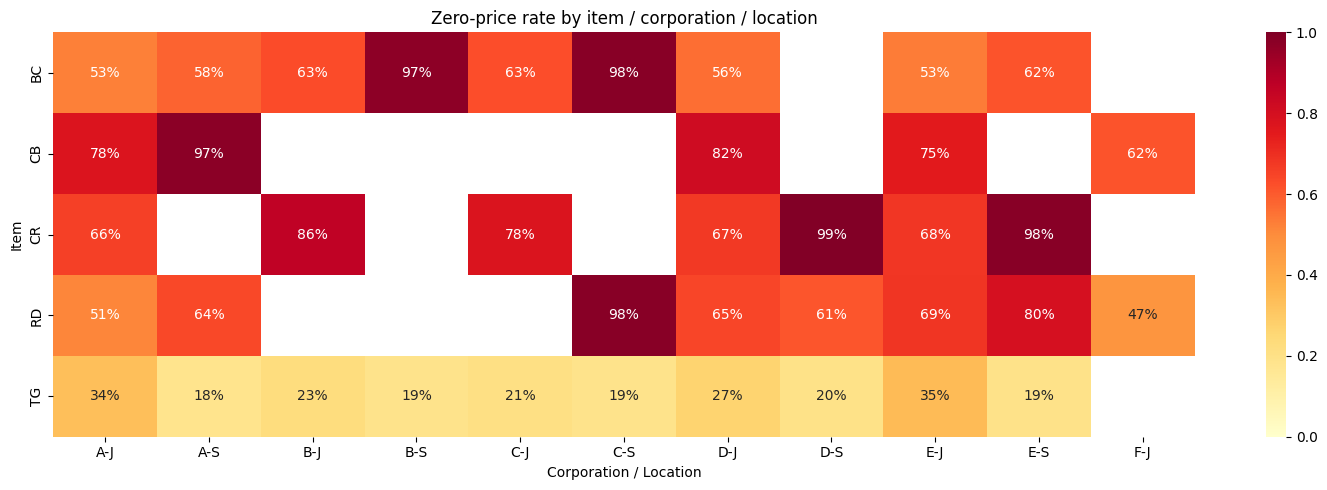

In [10]:
# 품목·법인·지역별 가격 0 비율
series_zero = (
    train.assign(is_zero=train["price(원/kg)"].eq(0))
    .groupby(["item", "corporation", "location"], observed=True)["is_zero"]
    .mean()
    .reset_index(name="zero_rate")
)
zero_pivot = series_zero.pivot_table(
    index="item", columns=["corporation", "location"], values="zero_rate"
)

plt.figure(figsize=(15, 5))
sns.heatmap(zero_pivot, annot=True, fmt=".0%", cmap="YlOrRd", vmin=0, vmax=1)
plt.title("Zero-price rate by item / corporation / location")
plt.xlabel("Corporation / Location")
plt.ylabel("Item")
plt.tight_layout()
plt.show()

**가격 분포**

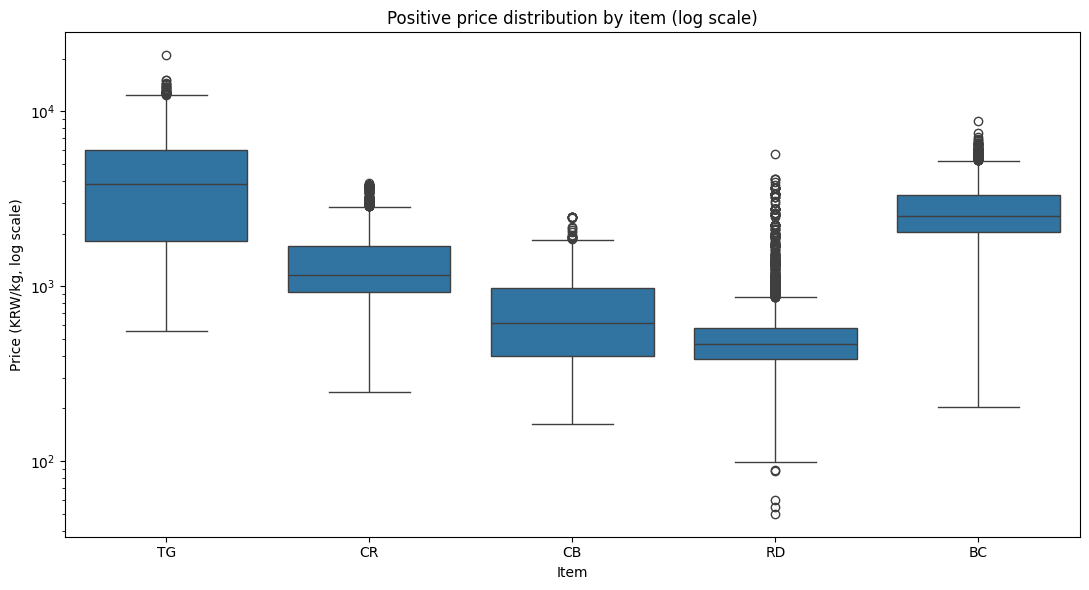

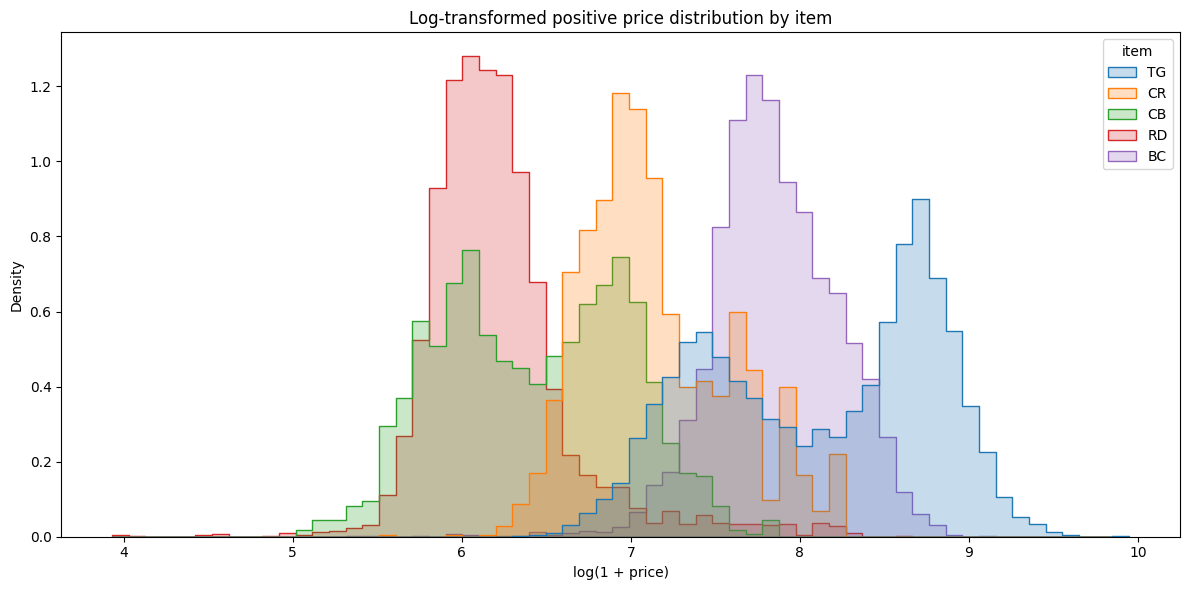

In [11]:
positive_train = train[train["price(원/kg)"].gt(0)].copy()

plt.figure(figsize=(11, 6))
sns.boxplot(data=positive_train, x="item", y="price(원/kg)")
plt.yscale("log")
plt.title("Positive price distribution by item (log scale)")
plt.xlabel("Item")
plt.ylabel("Price (KRW/kg, log scale)")
plt.tight_layout()
plt.show()

# 양수 가격 로그 분포
positive_train["log_price"] = np.log1p(positive_train["price(원/kg)"])
plt.figure(figsize=(12, 6))
sns.histplot(data=positive_train, x="log_price", hue="item", element="step", stat="density", common_norm=False)
plt.title("Log-transformed positive price distribution by item")
plt.xlabel("log(1 + price)")
plt.tight_layout()
plt.show()

**월별 가격 추세 및 공급량**

월별 집계에서는 다음 지표를 분리

  - mean_price_all: 거래가 없는 날의 0을 포함한 평균 가격
  - mean_price_positive: 가격이 양수인 관측치만의 평균 가격
  - zero_rate: 가격이 0인 비율
  - supply_weighted_price: 공급량으로 가중한 평균 가격

,month_start,item,mean_price_all,mean_price_positive,zero_rate,total_supply,price_supply_sum,supply_weighted_price
0,2019-01-01,BC,1278.086022,2049.344828,0.376344,695871.0,1.417513e+09,2037.034111
1,2019-01-01,CB,199.554839,391.531646,0.490323,3408100.0,1.378186e+09,404.385449
2,2019-01-01,CR,519.852535,1116.910891,0.534562,2370540.0,2.618594e+09,1104.640251
3,2019-01-01,RD,239.330645,359.721212,0.334677,13685460.0,4.701851e+09,343.565407
4,2019-01-01,TG,1485.383871,1841.876000,0.193548,14704526.7,2.817128e+10,1915.823606


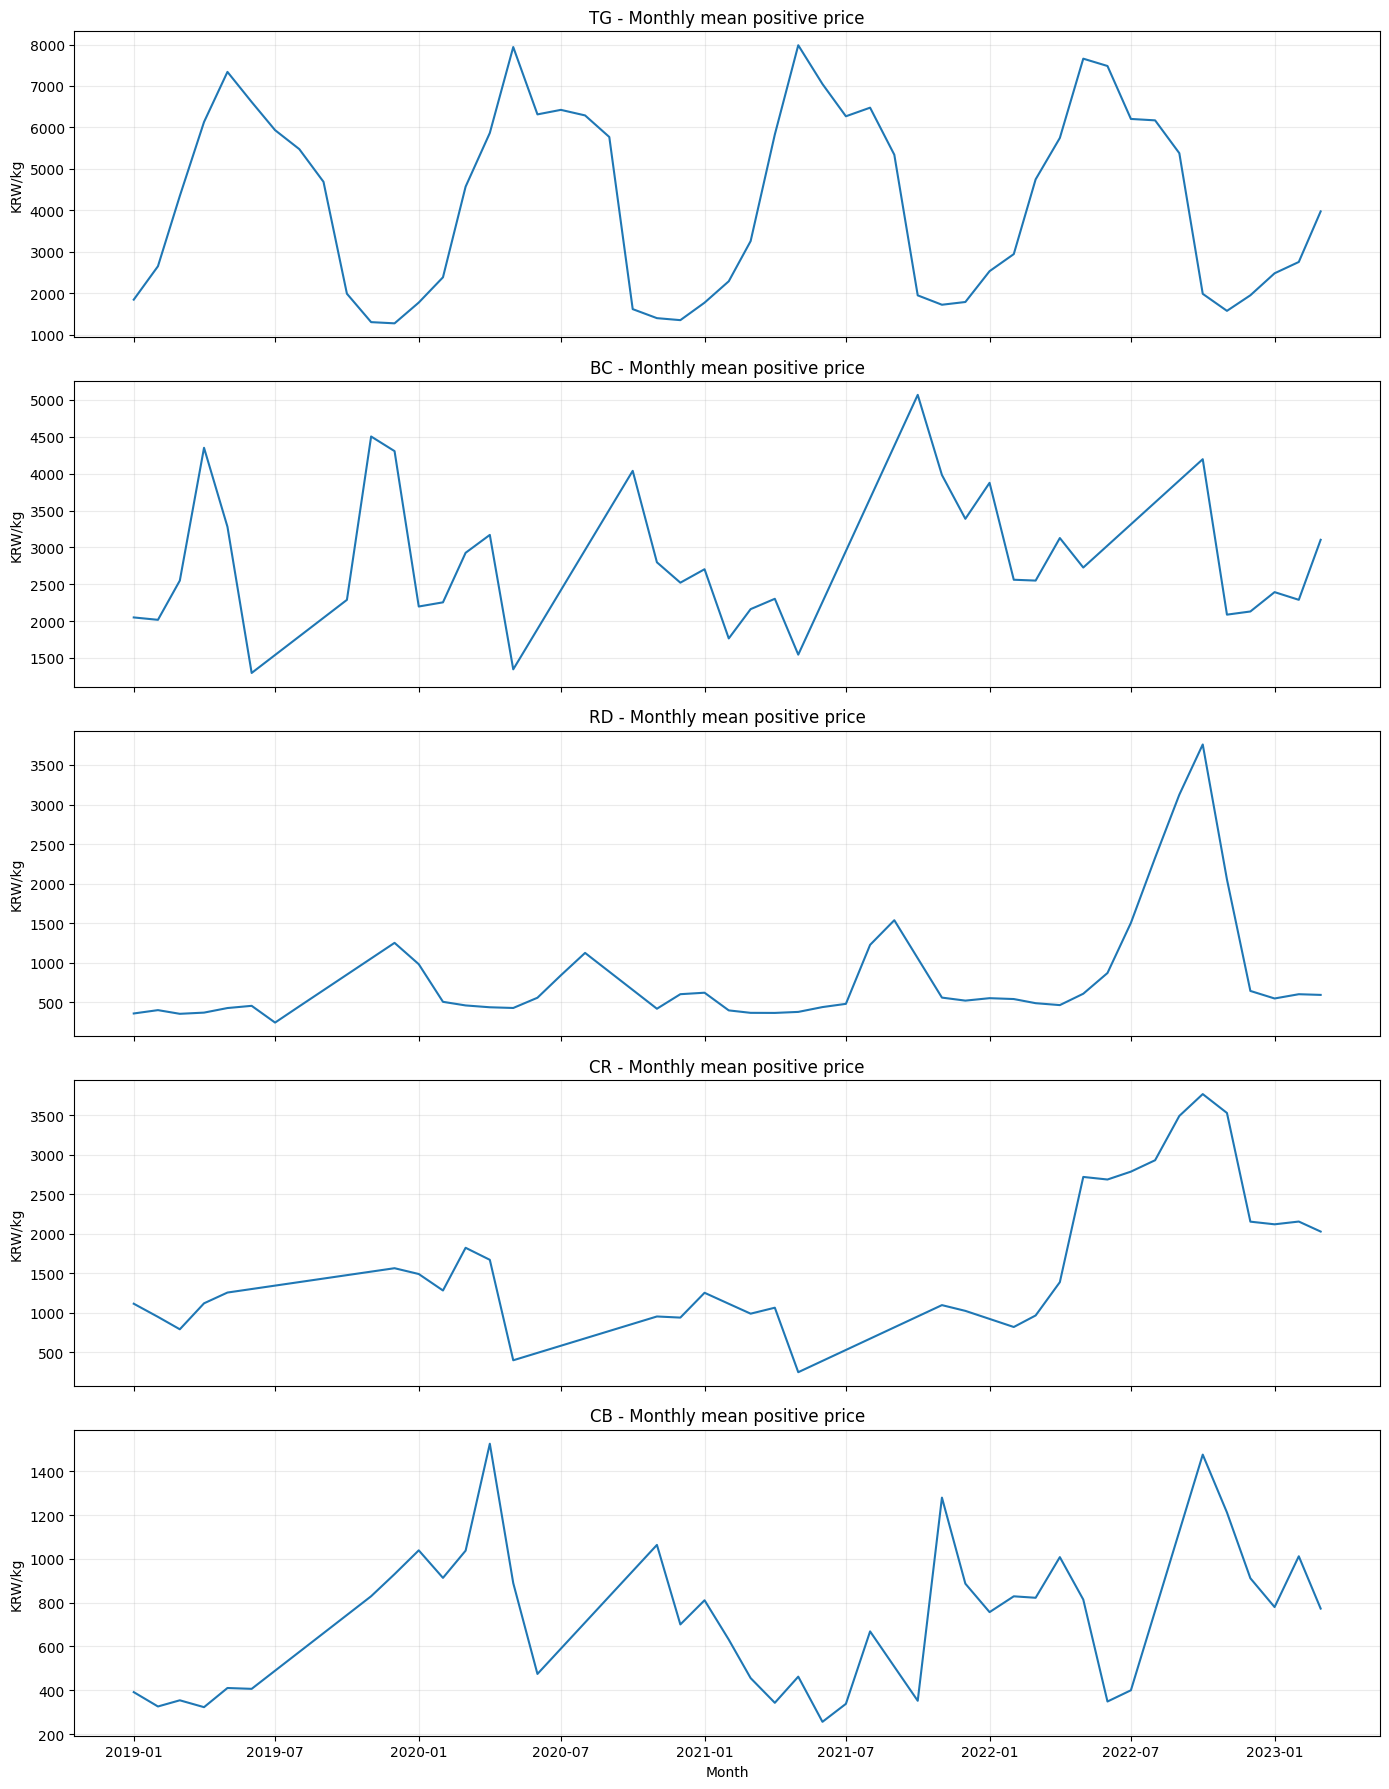

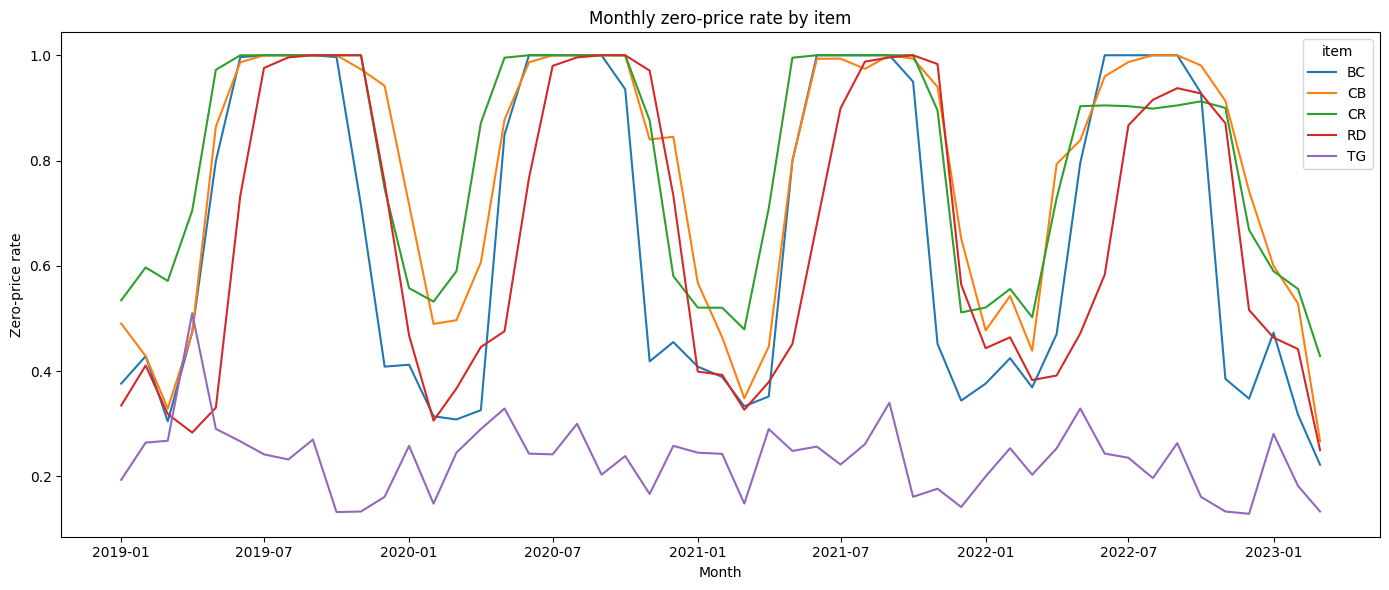

In [12]:
eda_daily = train.copy()
eda_daily["month_start"] = eda_daily["timestamp"].dt.to_period("M").dt.to_timestamp()
eda_daily["positive_price"] = eda_daily["price(원/kg)"].where(eda_daily["price(원/kg)"].gt(0))
eda_daily["price_times_supply"] = eda_daily["price(원/kg)"] * eda_daily["supply(kg)"]
eda_daily["is_zero_price"] = eda_daily["price(원/kg)"].eq(0).astype(int)

monthly_eda = eda_daily.groupby(["month_start", "item"], as_index=False).agg(
    mean_price_all=("price(원/kg)", "mean"),
    mean_price_positive=("positive_price", "mean"),
    zero_rate=("is_zero_price", "mean"),
    total_supply=("supply(kg)", "sum"),
    price_supply_sum=("price_times_supply", "sum"),
)
monthly_eda["supply_weighted_price"] = np.where(
    monthly_eda["total_supply"] > 0,
    monthly_eda["price_supply_sum"] / monthly_eda["total_supply"],
    np.nan,
)

display(monthly_eda.head())

# 품목별 양수 가격 평균의 월별 추세
items = ["TG", "BC", "RD", "CR", "CB"]
fig, axes = plt.subplots(len(items), 1, figsize=(14, 18), sharex=True)
for ax, item in zip(axes, items):
    d = monthly_eda[monthly_eda["item"] == item]
    sns.lineplot(data=d, x="month_start", y="mean_price_positive", ax=ax)
    ax.set_title(f"{item} - Monthly mean positive price")
    ax.set_ylabel("KRW/kg")
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Month")
plt.tight_layout()
plt.show()

# 품목별 월간 가격 0 비율 추세
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_eda, x="month_start", y="zero_rate", hue="item")
plt.title("Monthly zero-price rate by item")
plt.ylabel("Zero-price rate")
plt.xlabel("Month")
plt.tight_layout()
plt.show()

**월별 계절성**

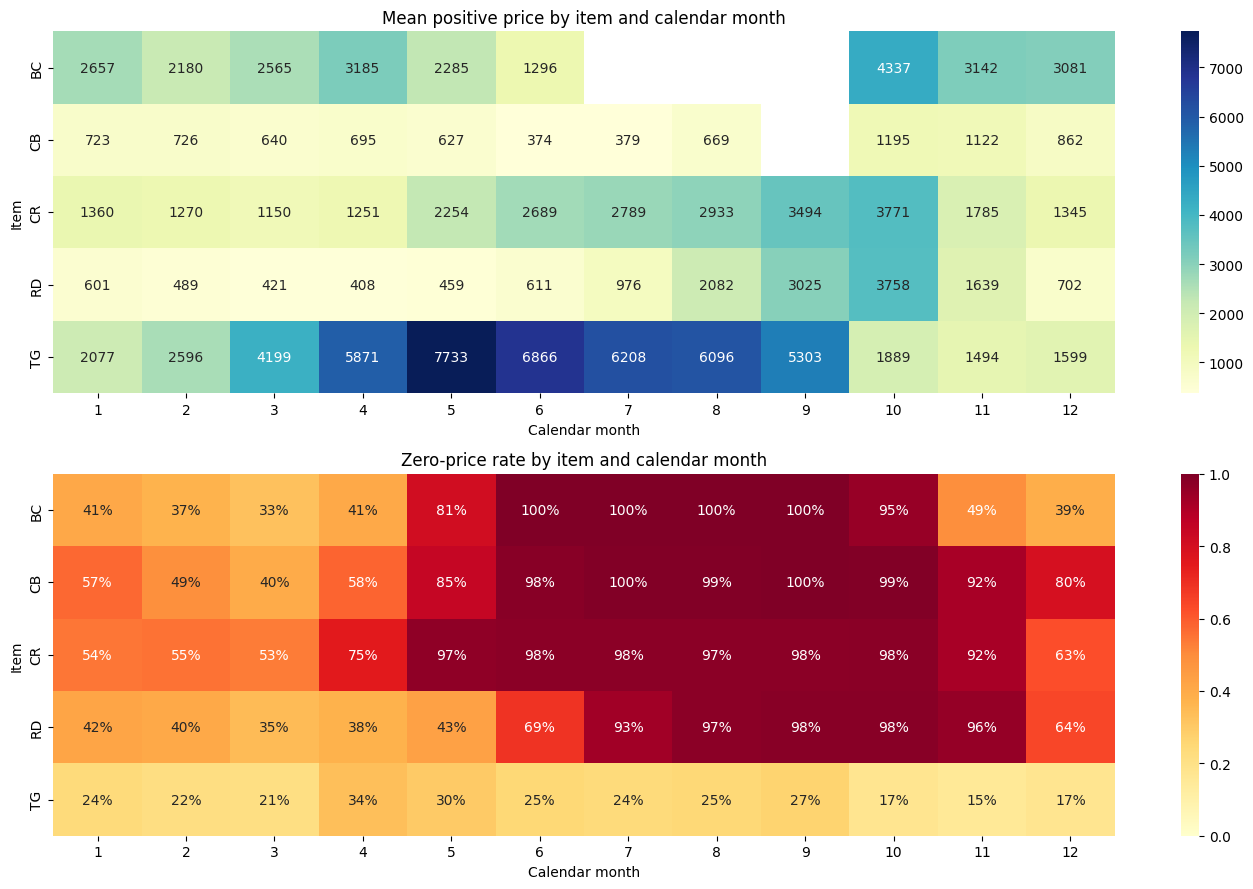

In [13]:
eda_daily["month_num"] = eda_daily["timestamp"].dt.month
seasonality = eda_daily.groupby(["item", "month_num"], as_index=False).agg(
    positive_price_mean=("positive_price", "mean"),
    zero_rate=("is_zero_price", "mean"),
)

price_season_pivot = seasonality.pivot(index="item", columns="month_num", values="positive_price_mean")
zero_season_pivot = seasonality.pivot(index="item", columns="month_num", values="zero_rate")

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
sns.heatmap(price_season_pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Mean positive price by item and calendar month")
axes[0].set_xlabel("Calendar month")
axes[0].set_ylabel("Item")

sns.heatmap(zero_season_pivot, annot=True, fmt=".0%", cmap="YlOrRd", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Zero-price rate by item and calendar month")
axes[1].set_xlabel("Calendar month")
axes[1].set_ylabel("Item")
plt.tight_layout()
plt.show()

**공급량과 가격의 관계**

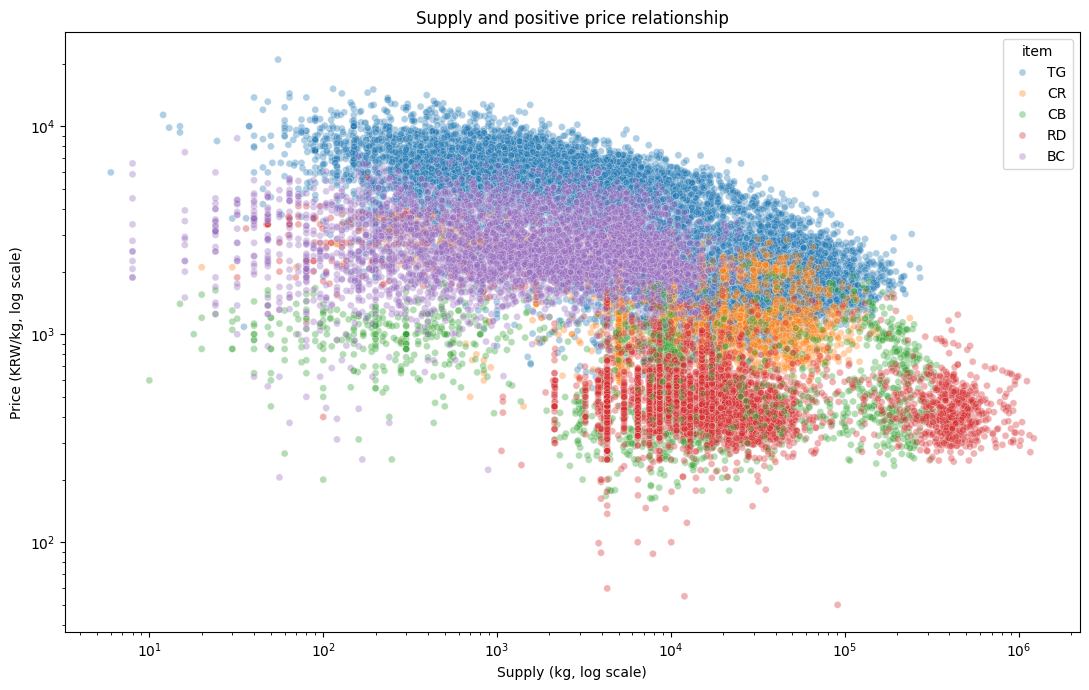

전체 상관계수:
             supply(kg)  price(원/kg)
supply(kg)     1.000000    -0.002297
price(원/kg)   -0.002297     1.000000
\n공급량 양수인 행의 상관계수:
             supply(kg)  price(원/kg)
supply(kg)     1.000000    -0.269334
price(원/kg)   -0.269334     1.000000
\n품목별 상관계수 (공급량 양수인 행):
item
BC   -0.153984
CB   -0.126217
CR   -0.252621
RD   -0.129281
TG   -0.521646
dtype: float64


/tmp/ipykernel_12289/2479184318.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(nonzero_supply.groupby("item").apply(lambda g: g["supply(kg)"].corr(g["price(원/kg)"])))


In [14]:
nonzero_supply = train[train["supply(kg)"].gt(0)].copy()

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=nonzero_supply,
    x="supply(kg)",
    y="price(원/kg)",
    hue="item",
    alpha=0.35,
    s=25,
)
plt.xscale("log")
plt.yscale("log")
plt.title("Supply and positive price relationship")
plt.xlabel("Supply (kg, log scale)")
plt.ylabel("Price (KRW/kg, log scale)")
plt.tight_layout()
plt.show()

print("전체 상관계수:")
print(train[["supply(kg)", "price(원/kg)"]].corr())
print("\\n공급량 양수인 행의 상관계수:")
print(nonzero_supply[["supply(kg)", "price(원/kg)"]].corr())

print("\\n품목별 상관계수 (공급량 양수인 행):")
print(nonzero_supply.groupby("item").apply(lambda g: g["supply(kg)"].corr(g["price(원/kg)"])))

**국제 거래 데이터 추세**

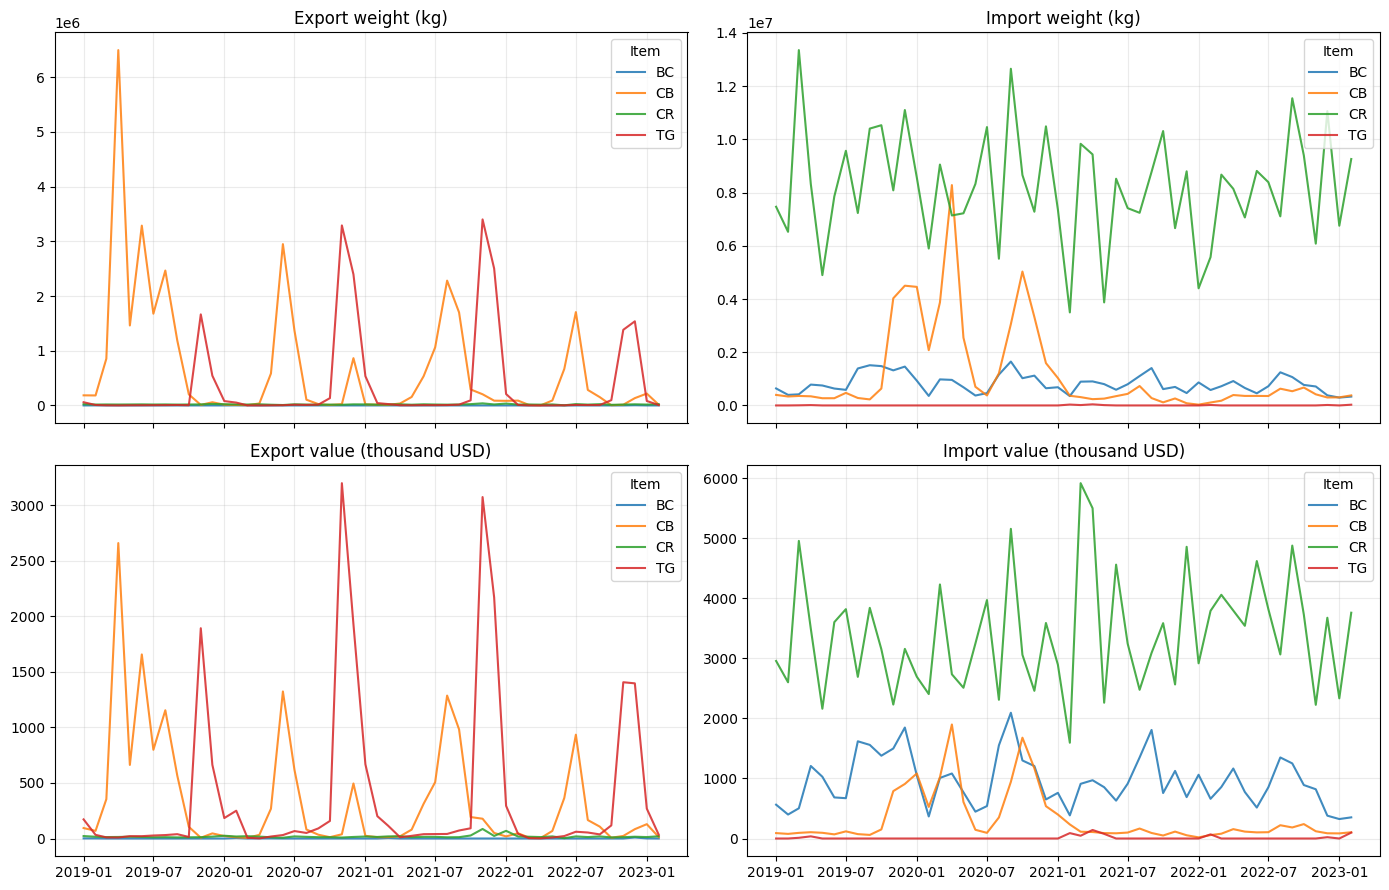

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
trade_plot_cols = [
    ("export_weight_kg", "Export weight (kg)"),
    ("import_weight_kg", "Import weight (kg)"),
    ("export_value_thousand_usd", "Export value (thousand USD)"),
    ("import_value_thousand_usd", "Import value (thousand USD)"),
]

for ax, (col, title) in zip(axes.flat, trade_plot_cols):
    for item, d in trade_used.groupby("item"):
        ax.plot(d["trade_month"], d[col], label=item, alpha=0.85)
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(title="Item")
plt.tight_layout()
plt.show()

### 전처리 데이터 저장

In [17]:
# 저장 폴더
OUTPUT_DIR = DATA_DIR / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_out = OUTPUT_DIR / "train_preprocessed.csv"
test_out = OUTPUT_DIR / "test_preprocessed.csv"
monthly_out = OUTPUT_DIR / "monthly_eda_summary.csv"
trade_out = OUTPUT_DIR / "international_trade_matched.csv"

train_prepared.to_csv(train_out, index=False, encoding="utf-8-sig")
test_prepared.to_csv(test_out, index=False, encoding="utf-8-sig")
monthly_eda.to_csv(monthly_out, index=False, encoding="utf-8-sig")
trade_used.to_csv(trade_out, index=False, encoding="utf-8-sig")

print("저장 완료")
for path in [train_out, test_out, monthly_out, trade_out]:
    print(path)

저장 완료
/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/processed/train_preprocessed.csv
/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/processed/test_preprocessed.csv
/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/processed/monthly_eda_summary.csv
/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/processed/international_trade_matched.csv


학습 데이터에는 타깃과 학습 기간의 공급량이 포함되어 있음

테스트 데이터에는 원본에서 제공되지 않은 가격·공급량을 만들지 않음

주의: 같은 날짜의 supply(kg)는 테스트 데이터에 존재하지 않으므로, 이후 모델 입력 변수로 그대로 사용하면 학습·테스트 변수 불일치가 발생. 공급량은 EDA에서 분석하고, 모델에 사용하려면 예측 시점에 실제로 알 수 있는 과거 공급량 등으로 별도 설계해야 함